In [1]:
# Importing librariesimport pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score


In [7]:
# Load dataset
df = pd.read_csv(r"C:\Users\USER\Downloads\stud.csv")

In [9]:
# Display first 5 rows
print(df.head())


   gender race_ethnicity parental_level_of_education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test_preparation_course  math_score  reading_score  writing_score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  


In [11]:
# Check column names
print(df.columns)

Index(['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score'],
      dtype='object')


In [13]:
# Check missing values
print(df.isnull().sum())

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64


In [15]:
# Check missing values
print(df.isnull().sum())

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64


In [19]:
# Input and output
X = df[["reading_score"]]
y = df["math_score"]

print(X.head())
print(y.head())

   reading_score
0             72
1             90
2             95
3             57
4             78
0    72
1    69
2    90
3    47
4    76
Name: math_score, dtype: int64


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 1)
Testing data: (200, 1)


In [23]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)
print("Model trained successfully!")

Slope: 0.8465291474700292
Intercept: 7.61591514772212
Model trained successfully!


In [25]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Math Score": y_test.values,
    "Predicted Math Score": y_pred.round(2)
})

print(results.head(10))

   Actual Math Score  Predicted Math Score
0                 91                 80.42
1                 53                 63.49
2                 80                 69.41
3                 74                 72.80
4                 84                 77.88
5                 81                 71.11
6                 69                 66.87
7                 54                 59.25
8                 87                 69.41
9                 51                 53.33


In [27]:
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 7.280881770618455
R2 Score: 0.6804469009921285


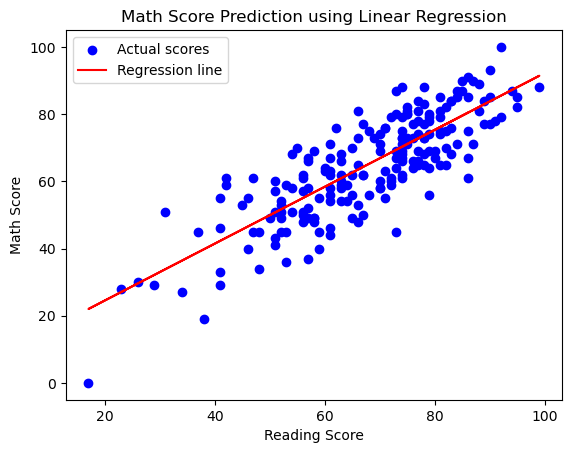

In [29]:
plt.scatter(X_test["reading_score"], y_test,
            color="blue", label="Actual scores")

plt.plot(X_test["reading_score"], y_pred,
         color="red", label="Regression line")

plt.xlabel("Reading Score")
plt.ylabel("Math Score")
plt.title("Math Score Prediction using Linear Regression")
plt.legend()
plt.show()

In [33]:
new_student = pd.DataFrame({
    "reading_score": [80]
})
prediction = model.predict(new_student)

print("Reading Score: 80")
print("Predicted Math Score:", round(prediction[0], 2))

Reading Score: 80
Predicted Math Score: 75.34
